# [Lab Session 2](otsu.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [2]:
imgf = plt.imread("data/NIH3T3/im/dna-0.png")

**[Task 1.2.]()** Quantify the image into 256 bins:

In [3]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [14]:
h = np.zeros(256)

for i in range(256):
   count = np.sum(img8 == i)
   h[i] = count

Show the computed histogram:

<BarContainer object of 256 artists>

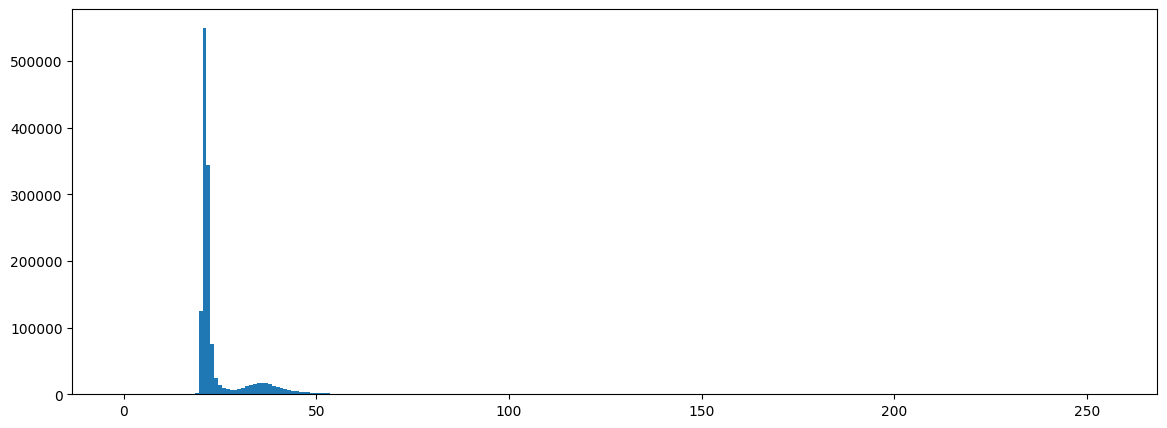

In [15]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [23]:
T_min = np.zeros(256)

for T in range(1,256):
    n1 = np.sum(h[range(0, T)])
    n2 = np.sum(h[range(T, 256)])
    var1 = np.var(img8[img8 < T])
    var2 = np.var(img8[img8 >= T])
    T_opt = n1*var1 + n2*var2
    T_min[T]=T_opt

print(np.argmin(T_min))

1


**[Task 1.5.]()** Perform Otsu thresholding:

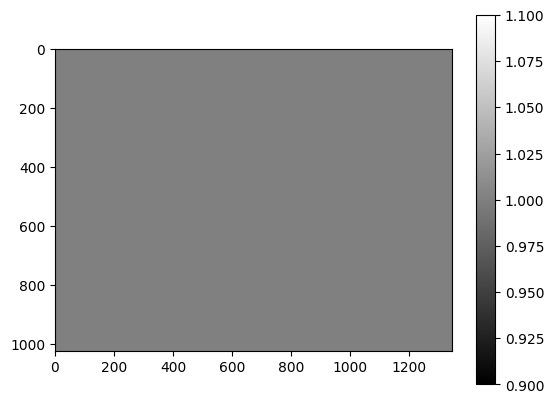

In [25]:
thres = 1
otsu_image = img8 >= thres
plt.figure()
plt.imshow(otsu_image, cmap='gray')
plt.colorbar()
plt.show()


**[Task 1.6.]()** Compute the Dice coefficient:

In [ ]:
ground_truth = plt.imread("data/NIH3T3/gt/0.png")
ground_truth_bool = ground_truth == 1

G = otsu_image
H = ground_truth_bool

print(otsu_image.dtype)
print(ground_truth_bool.dtype)

dice = 2*(G*H).sum()/(G.sum()+H.sum())
print(dice)